# FCC-ee baseline and pair-bias soft fusion

Compare the six-class baseline090 tagger with a no-kaon pair-bias light-flavour specialist combined through soft fusion. This notebook uses saved model predictions for 180,000 simulated jets and reproduces accuracy, confusion matrices and light-flavour working points. It requires no ROOT files, checkpoints or GPU.

The class order is `b, c, s, u, d, g`. The saved predictions come from the baseline and pair-bias experiments. Checkpoints were selected by validation loss. All seven feature configurations were also compared on the same test sample used for the final comparison, so these results do not provide an independent test of feature-set selection.

## Model comparison

The baseline supplies the total light-flavour probability

$$P_{\mathrm{light}}=P_6(s)+P_6(u)+P_6(d).$$

The specialist redistributes this mass:

$$P_{\mathrm{fusion}}(s/u/d)=P_{\mathrm{light}}\,P_{\mathrm{UDS}}(s/u/d),$$

while the `b`, `c` and `g` scores remain those of the baseline. The no-kaon configuration excludes explicit kaon-pair features from the attention-bias branch; the token-level baseline090 kaon-ID input is retained.

We compare the overall accuracy, mean per-class recall (macro accuracy), class recalls, pairwise ranking and signal efficiency at fixed background efficiency. The figures and tables use the same functions as `scripts/reproduce_results.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'scripts' / 'reproduce_results.py').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from within the repository.')
sys.path.insert(0, str(ROOT / 'scripts'))
from reproduce_results import (
    CLASS_NAMES, comparison_tables, load_results, plot_ablation, plot_comparison,
)

%matplotlib inline


## Load saved predictions

The loader checks the class order, label sequence and equality of the complete baseline score array between the two archives. It also checks probability normalisation and reconstructs the fusion from its component scores. These are consistency checks on the saved arrays; the prediction archives do not contain independent event identifiers.

In [2]:
results = load_results(ROOT / 'results' / 'final')
labels = results['labels']
counts = np.bincount(labels, minlength=len(CLASS_NAMES))
display(pd.DataFrame({'class': CLASS_NAMES, 'jets': counts}))
print(f'Total evaluation jets: {len(labels):,}')

,class,jets
0,b,29945
1,c,30003
2,s,29775
3,u,30083
4,d,30222
5,g,29972


Total evaluation jets: 180,000


## Accuracy and light-flavour discrimination

Per-class accuracy is the recall within each true flavour. Macro accuracy averages those recalls with equal class weights. The ROC panel shows signal efficiency on the horizontal axis and background efficiency on the vertical axis.

,model,overall_%,macro_%,b_%,c_%,s_%,u_%,d_%,g_%
0,baseline090,61.281,61.353,91.067,80.185,64.282,38.065,22.745,71.774
1,no_kaon_soft_fusion,62.476,62.527,91.074,80.122,60.380,35.917,36.602,71.070
2,delta_pp_improved_minus_baseline,1.196,1.174,0.007,-0.063,-3.903,-2.147,13.857,-0.704


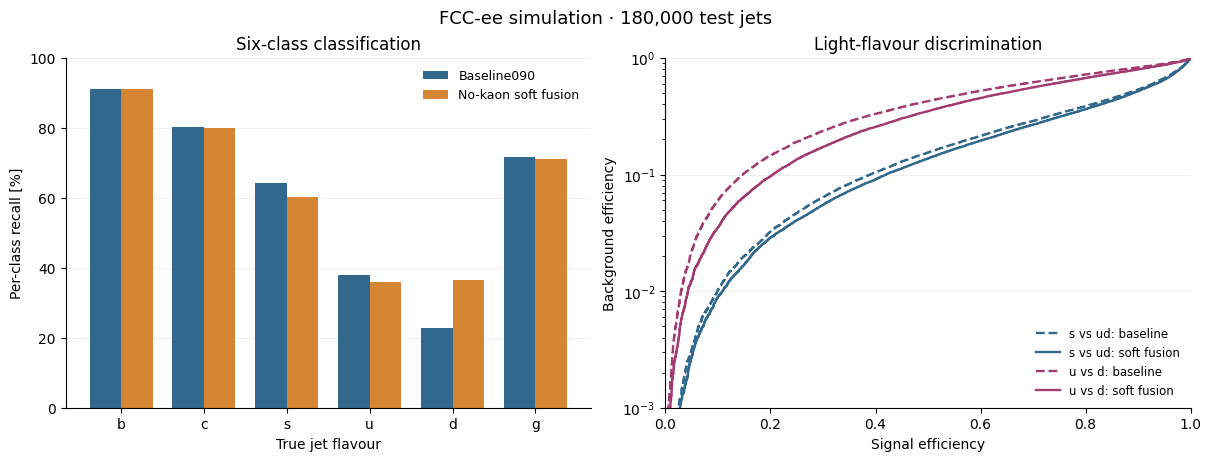

In [3]:
accuracy, working_points = comparison_tables(results)
display(accuracy.round(3))
fig = plot_comparison(results, accuracy)
plt.show()

## Confusion matrices

Rows are true flavours and columns are predicted flavours. Each row is normalised to 100%; the third panel is the change in percentage points.

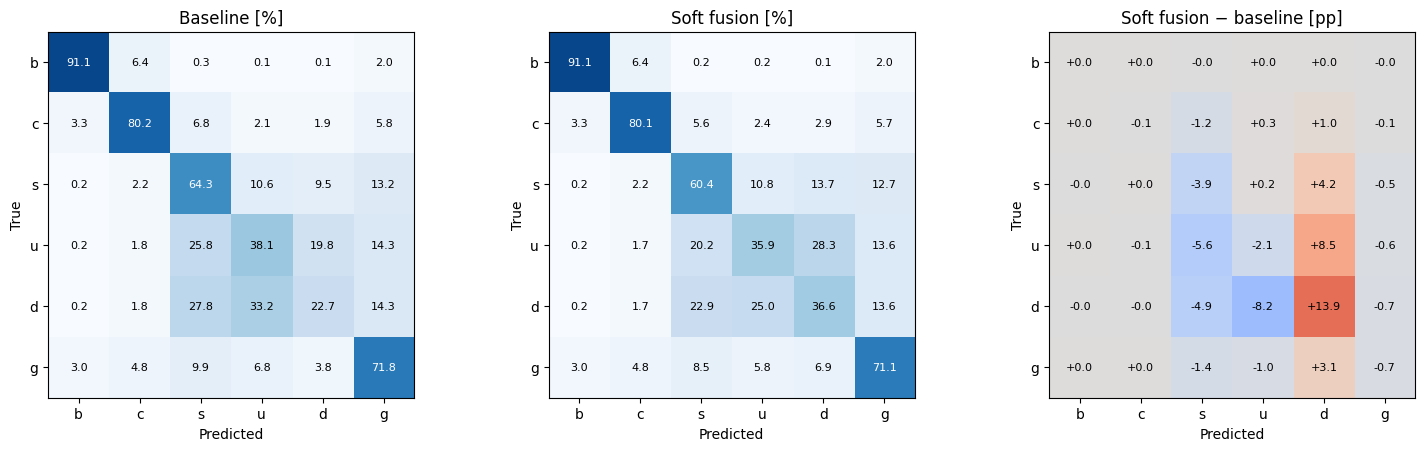

In [4]:
from djt.metrics import row_normalised_confusion_from_scores
from djt.plotting import plot_confusion_matrix

baseline_cm = row_normalised_confusion_from_scores(results['baseline_scores'], labels, 6)
fusion_cm = row_normalised_confusion_from_scores(results['fused_scores'], labels, 6)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout='constrained')
plot_confusion_matrix(axes[0], baseline_cm, CLASS_NAMES, 'Baseline [%]')
plot_confusion_matrix(axes[1], fusion_cm, CLASS_NAMES, 'Soft fusion [%]')
plot_confusion_matrix(
    axes[2], fusion_cm - baseline_cm, CLASS_NAMES, 'Soft fusion − baseline [pp]',
    cmap='coolwarm', vmin=-20, vmax=20, fmt='+.1f', text_threshold=1e9,
)
plt.show()

## Working points

For a pair of flavours $i,j$, the discriminant is $S_i/(S_i+S_j)$. For `s vs ud`, it is $S_s/(S_s+S_u+S_d)$; for `g vs q`, it is $S_g$ with all five quark flavours as background.

A threshold is the background-score quantile at $1-\epsilon_{\mathrm{background}}$, computed on this evaluation sample. Signal efficiency is the fraction of signal scores at or above that threshold. The table reproduces these empirical working points; finite sample size and tied scores can make the achieved background efficiency differ slightly from its target.

In [5]:
display(working_points.round(4))

,task,background_eff_%,baseline_sig_eff_%,fusion_sig_eff_%,delta_pp,baseline_threshold,fusion_threshold
0,b vs c,10.0,96.2565,96.2565,0.0000,0.2032,0.2032
1,b vs c,1.0,84.9858,84.9858,0.0000,0.8566,0.8566
2,b vs c,0.1,69.3004,69.3004,0.0000,0.9876,0.9876
3,c vs s,10.0,90.7109,90.8342,0.1233,0.2561,0.2703
4,c vs s,1.0,80.7453,81.0019,0.2566,0.8656,0.8684
5,c vs s,0.1,63.9069,64.5235,0.6166,0.9918,0.9912
6,s vs ud,10.0,38.9488,41.9782,3.0294,0.5384,0.5437
7,s vs ud,1.0,9.9144,10.8682,0.9538,0.7835,0.7999
8,s vs ud,0.1,2.4282,2.7842,0.3560,0.9051,0.9133
9,u vs d,10.0,14.7226,20.4268,5.7042,0.5418,0.6085


## Interpretation

Overall accuracy rises from 61.281% to 62.476%, and macro accuracy from 61.353% to 62.527%. The main recall gain is for `d` jets (22.745% to 36.602%), with decreases for `s` and `u`. Keeping the `b/c/g` scores fixed does not guarantee unchanged hard classifications, because their competitors in the final argmax change.

At 10% background efficiency, `s vs ud` signal efficiency rises from 38.949% to 41.978%, and `u vs d` from 14.723% to 20.427%. These describe the saved evaluation sample; no independent final sample or repeated-seed uncertainty study is included here.

Kinematic dependence requires the separate metadata export and is outside this notebook. The companion ablation notebook shows the evidence behind the chosen pair-feature configuration.